# 1. Considera el problema del laberinto y la rata que se mueve a través de él para llegar a la comida. Utilizando el código visto en clase (o una implementación propia), genera $1000$ trayectorias independientes y realiza lo siguiente:

## Codigo visto en clase a python

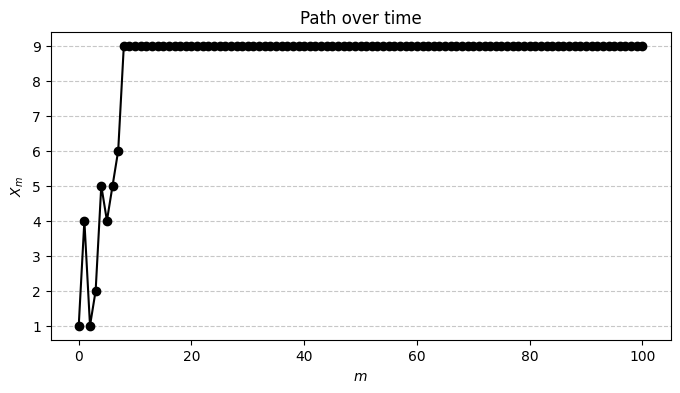

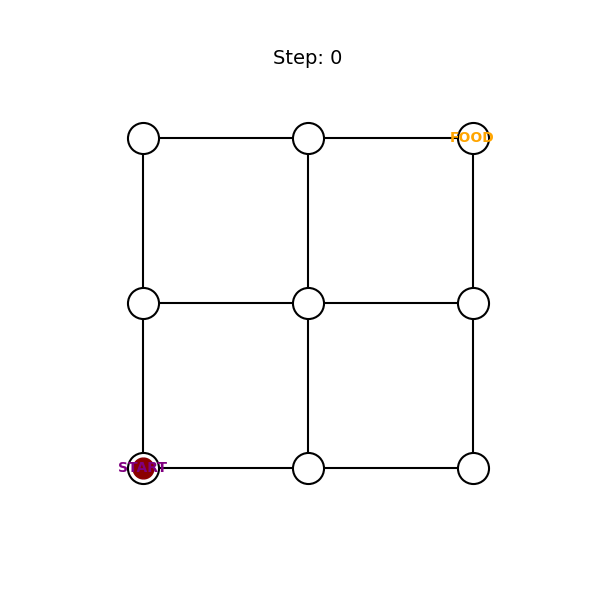

In [13]:
############################################################
# Markov Chain : Rat maze
# Translation to Python
############################################################

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image, display

############################################################
# 3 x 3 Maze

# States (R's expand.grid varies the first argument fastest)
# State 1 to 9 mapped to coordinates (x, y)
nodes = [(x, y) for y in range(1, 4) for x in range(1, 4)]

def plot_base_maze(ax):
    # Plot Horizontal paths
    for y in range(1, 4):
        for x in range(1, 3):
            ax.plot([x, x+1], [y, y], color='black', linewidth=1.5, zorder=1)

    # Plot Vertical paths
    for x in range(1, 4):
        for y in range(1, 3):
            ax.plot([x, x], [y, y+1], color='black', linewidth=1.5, zorder=1)

    # Plot States (Nodes)
    xs = [n[0] for n in nodes]
    ys = [n[1] for n in nodes]
    ax.scatter(xs, ys, s=500, facecolors='white', edgecolors='black', linewidth=1.5, zorder=2)

    # Annotate Starting state and Food state
    ax.text(1, 1, "START", color='purple', fontweight='bold', fontsize=10, ha='center', va='center', zorder=3)
    ax.text(3, 3, "FOOD", color='orange', fontweight='bold', fontsize=10, ha='center', va='center', zorder=3)

    ax.set_xlim(0.6, 3.4)
    ax.set_ylim(0.6, 3.4)
    ax.set_aspect('equal')
    ax.axis('off')

# To view the static maze plot:
# fig, ax = plt.subplots()
# plot_base_maze(ax)
# plt.show()
############################################################

############################################################
# Transition matrix
p11 = [0, .5, 0, .5, 0, 0, 0, 0, 0]
p21 = [1/3, 0, 1/3, 0, 1/3, 0, 0, 0, 0]
p31 = [0, .5, 0, 0, 0, .5, 0, 0, 0]
p12 = [1/3, 0, 0, 0, 1/3, 0, 1/3, 0, 0]
p22 = [0, .25, 0, .25, 0, .25, 0, .25, 0]
p32 = [0, 0, 1/3, 0, 1/3, 0, 0, 0, 1/3]
p13 = [0, 0, 0, .5, 0, 0, 0, .5, 0]
p23 = [0, 0, 0, 0, 1/3, 0, 1/3, 0, 1/3]
p33 = [0, 0, 0, 0, 0, 0, 0, 0, 1]

P = np.array([p11, p21, p31, p12, p22, p32, p13, p23, p33])

def cadena_rata(m, seed = 29):
  path = np.zeros(m + 1, dtype=int)
  path[0] = 1
  np.random.seed(seed)
  for i in range(1, m + 1):
      current_idx = path[i-1] - 1
      new_pos = np.random.choice(np.arange(1, 10), p=P[current_idx])
      path[i] = new_pos
  return path

path = cadena_rata(100)
m = len(path) - 1

df_path = pd.DataFrame({'m': np.arange(m + 1), 'Xm': path})

fig_path, ax_path = plt.subplots(figsize=(8, 4))
ax_path.plot(df_path['m'], df_path['Xm'], marker='o', linestyle='-', color='black')
ax_path.set_yticks(np.arange(1, 10))
ax_path.set_xlabel('$m$')
ax_path.set_ylabel('$X_m$')
ax_path.grid(axis='y', linestyle='--', alpha=0.7)
ax_path.set_title("Path over time")
plt.show()

# Animation of the Markov Chain in the labyrinth
fig_anim, ax_anim = plt.subplots(figsize=(6, 6))
plot_base_maze(ax_anim)

# Initialize lines and points for animation
path_line, = ax_anim.plot([], [], color='darkred', linewidth=2.5, zorder=1.5)
current_point, = ax_anim.plot([], [], marker='o', color='darkred', markersize=15, zorder=2.5)

def update(frame):
    current_path = path[:frame+1]

    # Get coordinates for the path followed so far
    x_coords = [nodes[s-1][0] for s in current_path]
    y_coords = [nodes[s-1][1] for s in current_path]

    path_line.set_data(x_coords, y_coords)
    current_point.set_data([x_coords[-1]], [y_coords[-1]])
    ax_anim.set_title(f"Step: {frame}", fontsize=14)

    return path_line, current_point

animation_obj = animation.FuncAnimation(
    fig_anim, update, frames=m + 1, interval=1000, blit=True
)

# Save as GIF using Pillow (equivalent to gifski in this context)
animation_obj.save("Maze.gif", writer='pillow', fps=1)
plt.close(fig_anim)
display(Image(filename="Maze.gif"))
############################################################

## (a) Estima el número esperado de pasos requeridos por la rata para llegar a la comida y compara tu estimación con el resultado teórico exacto.

In [14]:
n = 1000
m = 999
X = np.zeros(shape = (n, m + 1))

for i in range(n):
  X[i, :] = cadena_rata(m, seed = i)

X[:5,:]

array([[1., 4., 7., ..., 9., 9., 9.],
       [1., 2., 5., ..., 9., 9., 9.],
       [1., 2., 1., ..., 9., 9., 9.],
       [1., 4., 7., ..., 9., 9., 9.],
       [1., 4., 5., ..., 9., 9., 9.]])

In [15]:
t = np.zeros(n)

for i in range(n):
  t[i] = np.where(X[i, :] == 9.0)[0][0]

t[:5], np.mean(t)

(array([14., 26., 50.,  6.,  4.]), np.float64(18.282))

Sabemos que los tiempos de primera visita estan dados por el sistema de ecuaciones $(I - P')T = 1$, donde $P'$ será la matríz $P$ sin el estado absorbente. Así tendremos que el tiempo de primera visita $t_1$ será

In [16]:
P_prima = P[:8, :8]
I = np.eye(8)
uno = np.ones(8)
tiempo_p_visita = np.linalg.solve(I - P_prima, uno)[0]
tiempo_p_visita

np.float64(17.999999999999993)

La estimacion se acerca m uch al valor teórico de $18$

## (b) Modifica el código visto en clase para que la rata se mueva libremente por todo el laberinto, es decir, sin considerar a la comida como un estado absorbente. Obtén la distribución estacionaria de la cadena. ¿En qué estado pasa más tiempo la rata?

In [33]:
p11 = [0, .5, 0, .5, 0, 0, 0, 0, 0]
p21 = [1/3, 0, 1/3, 0, 1/3, 0, 0, 0, 0]
p31 = [0, .5, 0, 0, 0, .5, 0, 0, 0]
p12 = [1/3, 0, 0, 0, 1/3, 0, 1/3, 0, 0]
p22 = [0, .25, 0, .25, 0, .25, 0, .25, 0]
p32 = [0, 0, 1/3, 0, 1/3, 0, 0, 0, 1/3]
p13 = [0, 0, 0, .5, 0, 0, 0, .5, 0]
p23 = [0, 0, 0, 0, 1/3, 0, 1/3, 0, 1/3]
p33 = [0, 0, 0, 0, 0, .5, 0, .5, 0]

P2 = np.array([p11, p21, p31, p12, p22, p32, p13, p23, p33])

In [47]:
def cadena_rata2(m, seed = 29):
  path = np.zeros(m + 1, dtype=int)
  path[0] = 1
  np.random.seed(seed)
  for i in range(1, m + 1):
      current_idx = path[i-1] - 1
      new_pos = np.random.choice(np.arange(1, 10), p=P2[current_idx])
      path[i] = new_pos
  return path

m = 999
n = 1000
X = np.zeros(shape = (n, m +1))
for i in range (n):
  X[i] = cadena_rata2(m, seed = i)

In [48]:
from scipy import stats

estadoPop = stats.mode(X, axis = 1)
estadoPop.mode

array([5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 4., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 8., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 8., 5., 5., 5., 5., 5., 5., 2.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 8., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5., 5.,
       5., 5., 5., 5., 5.

In [50]:
vals, counts = np.unique(X, return_counts = True)
vals, counts/1000000

(array([1., 2., 3., 4., 5., 6., 7., 8., 9.]),
 array([0.084186, 0.125303, 0.083256, 0.125302, 0.166433, 0.124754,
        0.083224, 0.124641, 0.082901]))

La distribucion estacionaria esta dada porla ecuación $\pi P = \pi$, donde $\pi$ es la distribucion estacionaria. Así llegamos a la ecuacion $(I - P^t) \pi = 0$. Además, requerímos que las soluciones sumen $1$, por otro lado, dado que varias de las filas de nuestra matriz son iguales, entonces el sistema es linealmente dependiente, por lo cual eliminar una de las filas no afectara el resultado.

In [45]:
I = np.eye(9)
M = I - P2.T
M[0] = np.ones(9)
cero = np.zeros(9)
cero[0] = 1

pi = np.linalg.solve(M, cero)
pi

array([0.08333333, 0.125     , 0.08333333, 0.125     , 0.16666667,
       0.125     , 0.08333333, 0.125     , 0.08333333])

Esto valores, son muy similares a los obtenidos con la simulacion, es decir, se cumple el teorema ergodico para cadenas de Markov.

## (c) Utilizando las $1000$ trayectorias, estima la distribución de $X_n$ para distintos valores de $n$ y estudia su comportamiento conforme $n$ aumenta. ¿Existe una distribución límite? En caso de existir, compárala con la distribución estacionaria.

In [55]:
def distribucion_n(X, n):
  X_n = X[:, n].astype(int)
  distribucion = np.bincount(X_n, minlength=9) / 1000
  return distribucion

distribucion_n(X, 50), distribucion_n(X, 100), distribucion_n(X, 51), distribucion_n(X, 101)

(array([0.   , 0.155, 0.   , 0.158, 0.   , 0.34 , 0.   , 0.159, 0.   ,
        0.188]),
 array([0.   , 0.173, 0.   , 0.173, 0.   , 0.347, 0.   , 0.155, 0.   ,
        0.152]),
 array([0.   , 0.   , 0.237, 0.   , 0.235, 0.   , 0.265, 0.   , 0.263]),
 array([0.   , 0.   , 0.262, 0.   , 0.245, 0.   , 0.261, 0.   , 0.232]))

No existe distribucion limite, ya que la matríz tiene periodo $d = 2$

## (d) Genera una trayectoria suficientemente larga y calcula la proporción del tiempo que la rata permanece en cada uno de los estados. Compara estas proporciones con la distribución estacionaria.

In [56]:
vals, counts = np.unique(X, return_counts = True)
vals, counts/1000000

(array([1., 2., 3., 4., 5., 6., 7., 8., 9.]),
 array([0.084186, 0.125303, 0.083256, 0.125302, 0.166433, 0.124754,
        0.083224, 0.124641, 0.082901]))

Confirmamos que se parecen parece a la distribución estacionaría, esto por el Teorema Ergódico para Cadenas de Markov, vitso en Procesos 1

# 2. Considera la cadena de Ehrenfest, llamada así en honor a Paul Ehrenfest, utilizada como un modelo sencillo para representar el intercambio de moléculas de gas entre dos urnas. Se tienen en total $N$ bolas -que representan las moléculas de gas- distribuidas entre dos urnas. En cada paso se elige una bola al azar y se cambia de urna. Si $X_n$ denota el número de bolas en la urna $A$ después de $n$ pasos, entonces $\{X_n\}_{n \ge 0}$ define una cadena de Markov.

## (a) Implementa un algoritmo que permita simular trayectorias de este proceso estocástico

In [125]:
def cadena_Ehrenfest(N, n, m, inicial = "random", seed = 29):
  np.random.seed(seed)
  if inicial == "random":
    inicial = np.random.choice(range(N + 1))
  X = np.zeros(shape = (m, n + 1))
  X[:, 0] = inicial
  for i in range(m):
    for j in range(1, n + 1):
      if X[i, j - 1] == 0:
        X[i, j] = 1
      elif X[i, j - 1] == N:
        X[i, j] = N-1
      else:
        bola = np.random.choice([1, -1], p = [(N - X[i, j - 1]) / N, X[i, j - 1] / N])
        X[i, j] = X[i, j - 1] + bola
  return X

In [126]:
cadena_Ehrenfest(10, 10, 10)

array([[5., 4., 5., 4., 5., 6., 7., 6., 5., 4., 3.],
       [5., 6., 7., 6., 5., 6., 7., 8., 7., 6., 5.],
       [5., 6., 5., 4., 5., 4., 5., 6., 5., 6., 7.],
       [5., 4., 3., 4., 3., 4., 3., 2., 3., 4., 3.],
       [5., 6., 5., 6., 5., 4., 5., 4., 5., 4., 3.],
       [5., 6., 7., 6., 5., 6., 5., 4., 3., 2., 3.],
       [5., 4., 3., 4., 5., 4., 3., 4., 5., 6., 5.],
       [5., 6., 7., 6., 5., 4., 5., 6., 5., 4., 3.],
       [5., 4., 3., 2., 3., 4., 5., 6., 5., 4., 5.],
       [5., 4., 5., 6., 7., 6., 5., 4., 3., 4., 5.]])

## (b) Para $N = 10$, construye la matriz de transición y obtén la distribución estacionaria de la cadena.

Sabemos que para el estado $0$, se mueve a $1$ con proba $1$, al igual que para el caso $10$, se mueve a $9$ con proba $1$. Finalmente, para $n \in {1, 2, ..., 9}$, se mueve a $n - 1$ y a $n + 1$ con proba $\frac{1}{N}$ y $\frac{N - n}{N}$ respectivamente. Así la matriz de transicion es

$$
P = \begin{pmatrix}
0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
\frac{1}{10} & 0 & \frac{9}{10} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & \frac{2}{10} & 0 & \frac{8}{10} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & \frac{3}{10} & 0 & \frac{7}{10} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & \frac{4}{10} & 0 & \frac{6}{10} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & \frac{5}{10} & 0 & \frac{5}{10} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & \frac{6}{10} & 0 & \frac{4}{10} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & \frac{7}{10} & 0 & \frac{3}{10} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & \frac{8}{10} & 0 & \frac{2}{10} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & \frac{9}{10} & 0 & \frac{1}{10} \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0
\end{pmatrix}
$$

Y la matriz estacionaria será

In [127]:
def dist_estacionaria(N):
  dim = N + 1
  P = np.zeros(shape = (dim, dim))
  for i in range(dim):
      if i != 0:
          P[i, i - 1] = i / N
      if i != N:
          P[i, i + 1] = (N - i) / N
  I = np.eye(dim)
  M = I - P.T
  M[0] = np.ones(dim)
  cero = np.zeros(dim)
  cero[0] = 1
  pi = np.linalg.solve(M, cero)
  return pi

dist_estacionaria(10)

array([0.00097656, 0.00976563, 0.04394531, 0.1171875 , 0.20507812,
       0.24609375, 0.20507813, 0.1171875 , 0.04394531, 0.00976563,
       0.00097656])

# (c) Genera $1000$ trayectorias independientes y estima la distribución de $X_n$ para distintos valores de $n$. Estudia su comportamiento conforme n aumenta. ¿Existe una distribución límite? En caso de existir, compárala con la distribución estacionaria

In [128]:
X = cadena_Ehrenfest(10, 999, 1000)

distribucion_n(X, 50), distribucion_n(X, 100), distribucion_n(X, 51), distribucion_n(X, 101)

(array([0.   , 0.021, 0.   , 0.21 , 0.   , 0.506, 0.   , 0.246, 0.   ,
        0.017]),
 array([0.   , 0.021, 0.   , 0.236, 0.   , 0.517, 0.   , 0.212, 0.   ,
        0.014]),
 array([0.003, 0.   , 0.078, 0.   , 0.392, 0.   , 0.437, 0.   , 0.089,
        0.   , 0.001]),
 array([0.001, 0.   , 0.096, 0.   , 0.414, 0.   , 0.412, 0.   , 0.077]))

Nuevamente, no existe una distribución limite, la cadena es periódica con periodo d = 2

## (d) Genera una trayectoria suficientemente larga y calcula la proporción del tiempo que la cadena permanece en cada estado. Compara estas proporciones con la distribución estacionaria

In [129]:
X = cadena_Ehrenfest(10, 999999, 1)

vals, counts = np.unique(X, return_counts = True)
vals, counts/1000000

(array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]),
 array([0.000945, 0.00959 , 0.043383, 0.116005, 0.20442 , 0.246926,
        0.206342, 0.117729, 0.04393 , 0.00975 , 0.00098 ]))

# 3. Sean $T_1, T_2, ...$ variables aleatorias independientes con distribución exponencial de parámetro $\lambda$, entonces definimos al proceso Poisson como

# $$X_t = \max\{n \ge 1 : T_1 + \dots + T_n \le t\},$$

# con $X_0 = 0$ por lo que se define $\max\{\emptyset\} = 0$.

## (a) Implementa un algoritmo que permita simular trayectorias de este proceso utilizando los tiempos entre eventos $T1, T2, ...$

In [130]:
def PPoisson(n, lam, t, seed = 29):
  X = np.zeros(n)
  for i in range(n):
    T = 0
    j = 0
    while T <= t:
      T += np.random.exponential(1/lam)
      j += 1
    X[i] = j -1
  return X

In [131]:
PPoisson(1, 10, 0), PPoisson(5, 1, 20)

(array([0.]), array([26., 18., 19., 22., 15.]))

## (b) A partir de $1000$ simulaciones independientes, muestra gráficamente y con la prueba de bondad de ajuste adecuada que, para un tiempo fijo $t$,

## $$X_t \sim \text{Poisson}(\lambda t).$$"""

In [132]:
tiempo = [1, 5, 10, 20, 50, 100]
X = np.zeros(shape = (1000, 6))

for i in range(6):
  X[:, i] = PPoisson(1000, 5, tiempo[i])

In [133]:
from scipy.stats import chisquare, poisson

for i, t in enumerate(tiempo):
    obs = np.bincount(X[:, i].astype(int))
    esp = 1000 * poisson.pmf(np.arange(len(obs)), 5 * t)

    val = esp > 0
    stat, p = chisquare(f_obs=obs[val], f_exp=esp[val] * (1000 / esp[val].sum()))
    print(f"t = {t}: Estadístico = {stat:.4f}, p-valor = {p:.4f}")

t = 1: Estadístico = 13.9236, p-valor = 0.3792
t = 5: Estadístico = 26.4593, p-valor = 0.9618
t = 10: Estadístico = 32.8042, p-valor = 1.0000
t = 20: Estadístico = 77.7762, p-valor = 1.0000
t = 50: Estadístico = 117.8671, p-valor = 1.0000
t = 100: Estadístico = 291.2414, p-valor = 1.0000


Dados los p-values mayores a nuesto $\alpha = 0.5$, vemos que $X_t \sim \text{Poisson}(\lambda t)$